In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
from time import time
from utils import generate_position, batch_sample

In [2]:
DEFAULT_DATA = '/home/hep/lprate/projects/MuonsAndMatter/data/muons/full_sample_w.h5'
device = 'cuda:0'

In [3]:
data = {}
with h5py.File(DEFAULT_DATA, 'r') as f:
    for group_name in f.keys():
        print(f"Group: {group_name}")
        group = f[group_name]
        weight = group.attrs['weight']
        if float(weight) < 0.0001: continue
        px = group['px'][:]
        py = group['py'][:]
        pz = group['pz'][:]
        x_ = group['x'][:]
        y_ = group['y'][:]
        z_ = group['z'][:]
        pdg = group['pdg'][:]
        data[weight] = np.stack([px, py, pz, x_, y_, z_, pdg], axis=1)
        print(f"Weight: {weight}, Shape: {data[weight].shape}")

del px, py, pz, x_, y_, z_, pdg
pz_real = np.concatenate([data[weight][:, 2] for weight in data.keys()])
pt_real = np.sqrt(np.concatenate([data[weight][:, 0]**2 + data[weight][:, 1]**2 for weight in data.keys()]))
weights = np.concatenate([np.full(data[w].shape[0], float(w), dtype=float) for w in data.keys()])


Group: 0
Group: 1
Weight: 0.09369999915361404, Shape: (3311, 7)
Group: 2
Weight: 1.0, Shape: (20993, 7)
Group: 3
Weight: 3.2616000175476074, Shape: (691113, 7)
Group: 4
Weight: 7.6875, Shape: (480474935, 7)
Group: 5
Weight: 9.369999885559082, Shape: (168445, 7)
Group: 6
Weight: 326.1600036621094, Shape: (11094133, 7)
Group: 7
Weight: 768.75, Shape: (13921031, 7)


In [4]:
from models import NeuralSplineFlow
models = torch.load('outputs/flow_model_per_w.pt', map_location='cpu', weights_only=False)["groups"]

In [5]:
for w, e in models.items():
    flow = NeuralSplineFlow.from_config(e["config"])
    flow.load_state_dict(e["state_dict"])
    flow.eval()
    flow.log_transform = True 
    e["flow"] = flow.to('cpu').eval()

In [ ]:
n_samples = 1e9
alpha = n_samples / sum([model['weight'] for model in models.values()])
gen_pz = []
gen_pt = []
for weight, model in models.items():
    real_weight = round(model['weight'] * alpha)
    if real_weight<1: continue
    flow = model['flow'].to(device)
    flow.eval()
    mean,std = model['mean'], model['std']
    t1 = time()
    print(f"Weight: {weight}")
    print("real_weight", real_weight)
    sample = batch_sample(flow, real_weight, mean = mean, std = std)
    print(f"Sampling {real_weight} samples took {time()-t1:.2f} seconds")
    gen_pz.append(sample[:, 0])
    gen_pt.append(sample[:, 1])

del sample, mean, std
gen_pz = np.concatenate(gen_pz)
gen_pt = np.concatenate(gen_pt)
print(f"Generated pz shape: {gen_pz.shape}, pt shape: {gen_pt.shape}")

In [6]:
from matplotlib.colors import LogNorm

def compare_1d_histograms(real_sample, gen_sample, bins=120, range_vals=None, xlabel="Value", real_w=None):
    """Overlays 1D distributions of real and generated samples."""
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # Auto-detect range if none is provided
    if range_vals is None:
        range_vals = (min(np.min(real_sample), np.min(gen_sample)), 
                      max(np.max(real_sample), np.max(gen_sample)))
        
    b = np.linspace(range_vals[0], range_vals[1], bins)
    
    # Plot marginals
    ax.hist(real_sample, bins=b, weights=real_w, density=True, 
            histtype='step', color='k', label='Real')
    ax.hist(gen_sample, bins=b, density=True, 
            histtype='step', color='C1', label='Generated')
    
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel('Density', fontsize=14)
    ax.legend(fontsize=11)
    
    fig.tight_layout()
    return fig, ax


def compare_2d_histograms(real_pz, real_pt, gen_pz, gen_pt, gen_pz_2 = None, gen_pt_2 = None, real_w=None):
    """Creates side-by-side 2D Pz-Pt density histograms with a shared color scale."""
    pz_bins = np.linspace(0, 400, 201)
    pt_bins = np.linspace(0, 13, 201)
    
    n_plots = 2 if gen_pz_2 is None else 3
    # Calculate 2D densities
    Hr, _, _ = np.histogram2d(real_pz, real_pt, bins=[pz_bins, pt_bins], 
                              weights=real_w, density=True)
    Hg, _, _ = np.histogram2d(gen_pz, gen_pt, bins=[pz_bins, pt_bins], 
                              density=True)
    if gen_pz_2 is not None:
        Hg2, _, _ = np.histogram2d(gen_pz_2, gen_pt_2, bins=[pz_bins, pt_bins], 
                                   density=True)
    
    # Shared LogNorm for accurate visual comparison
    pos_vals = np.concatenate([Hr[Hr > 0].ravel(), Hg[Hg > 0].ravel()])
    pos_vals = np.concatenate([pos_vals, Hg2[Hg2 > 0].ravel()]) if gen_pz_2 is not None else pos_vals
    norm = LogNorm(vmin=pos_vals.min(), vmax=pos_vals.max())
    sizes = [real_pz.shape[0], gen_pz.shape[0]] if gen_pz_2 is None else [real_pz.shape[0], gen_pz.shape[0], gen_pz_2.shape[0]]
    
    fig, axes = plt.subplots(1, n_plots, figsize=(12, 5), constrained_layout=True)
    
    # Draw meshes
    Hs = [Hr, Hg] if gen_pz_2 is None else [Hr, Hg, Hg2]
    titles = ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1])] if gen_pz_2 is None else ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1]), 'Generated Extra (n = {})'.format(sizes[2])]
    for ax, H, title in zip(axes, Hs, titles):
        im = ax.pcolormesh(pz_bins, pt_bins, H.T, cmap='viridis', norm=norm)
        ax.set_xlim(0, 400)
        ax.set_ylim(0, 13)
        ax.set_xlabel('$P_z$ [GeV]', fontsize=14)
        ax.set_ylabel('$P_t$ [GeV]', fontsize=14)
        ax.set_title(title, fontsize=14)
        
    # Shared colorbar
    fig.colorbar(im, ax=axes.tolist(), label='Density')
    
    return fig, axes

In [ ]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, real_w=weights)

In [ ]:
for w in data.keys():
    plt.hist(data[w][:,5], bins='auto', density=True, histtype='step',  label = str(w)[:4])
    print(f"Weight: {w}, mean Z Position: {np.mean(data[w][:,5]):.2f} cm, std Z Position: {np.std(data[w][:,5]):.2f} cm")
    plt.ylim(0, 6)
plt.legend(title='Weights', fontsize=10)
plt.xlabel('Z Position [cm]', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.show()

In [ ]:
for w in data.keys():
    print(f" ======================= WEIGHT {w} ======================= ")
    model = models[w]
    pz_real = np.concatenate([data[w][:, 2]])
    pt_real = np.sqrt(np.concatenate([data[w][:, 0]**2 + data[w][:, 1]**2]))
    n_samples = pz_real.shape[0]
    flow = model['flow'].to(device)
    mean,std = model['mean'], model['std']
    sample = batch_sample(flow, n_samples, mean = mean, std = std)
    gen_pz = sample[:, 0]
    gen_pt = sample[:, 1]
    n_samples = min(n_samples * 100, 8e8)
    sample = batch_sample(flow, n_samples, mean = mean, std = std)
    gen_pz_extra = sample[:, 0]
    gen_pt_extra = sample[:, 1]
    compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, gen_pz_2=gen_pz_extra, gen_pt_2=gen_pt_extra)
    plt.show()
    print(f"Number of real samples: {pz_real.shape[0]}, Number of generated samples: {gen_pz_extra.shape[0]}")
    print("\n \n")

# Single Model

In [7]:
model = torch.load('outputs/flow_model_2.pt', map_location='cpu', weights_only=False)["groups"]["combined"]
flow = NeuralSplineFlow.from_config(model["config"])
flow.load_state_dict(model["state_dict"])

<All keys matched successfully>

In [ ]:
n_samples = 1e9
flow = flow.to(device)
flow.eval()
mean,std = model['mean'], model['std']
t1 = time()
sample = batch_sample(flow, n_samples, mean = mean, std = std)
print(f"Sampling {real_weight} samples took {time()-t1:.2f} seconds")
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

del sample, mean, std
print(f"Generated pz shape: {gen_pz.shape}, pt shape: {gen_pt.shape}")

In [ ]:
pz_real = np.concatenate([data[weight][:, 2] for weight in data.keys()])
pt_real = np.sqrt(np.concatenate([data[weight][:, 0]**2 + data[weight][:, 1]**2 for weight in data.keys()]))
weights = np.concatenate([np.full(data[w].shape[0], float(w), dtype=float) for w in data.keys()])

In [ ]:
pz_real.shape, gen_pz.shape

In [ ]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, real_w=weights)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

# sample counts to test
n_values = np.unique(np.rint(np.geomspace(1e3, 1e8, 10)).astype(int))

# batch sizes to compare
batch_sizes = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]

flow = flow.to(device)
flow.eval()
mean, std = model["mean"], model["std"]

results = {bs: [] for bs in batch_sizes}

for bs in batch_sizes:
    for n in n_values:
        t0 = perf_counter()
        total = 0

        # chunk total n into batches of size bs
        while total < n:
            m = min(bs, n - total)
            sample = batch_sample(flow, m, mean=mean, std=std)
            total += m
            del sample

        elapsed = perf_counter() - t0
        results[bs].append((n, elapsed))
        print(f"batch_size={bs:>10,}  n={n:>12,}  time={elapsed:.3f}s")

plt.figure(figsize=(9, 6))
for bs, vals in results.items():
    ns = np.array([v[0] for v in vals], dtype=float)
    ts = np.array([v[1] for v in vals], dtype=float)
    plt.loglog(ns, ts, "o-", label=f"batch_size={bs:,}")

plt.xlabel("n_samples")
plt.ylabel("sampling time [s]")
plt.title("Sampling time vs. n_samples for different batch sizes")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

# Temperature Scaled Sampling

In [9]:
T = 1.5

n_samples = 10e6
flow = flow.to(device)
flow.eval()
mean,std = model['mean'], model['std']
t1 = time()
sample = batch_sample(flow, n_samples, mean = mean, std = std, temperature=T)
#print(f"Sampling {real_weight} samples took {time()-t1:.2f} seconds")
gen_pz = sample[:, 0]
gen_pt = sample[:, 1]

del sample, mean, std
print(f"Generated pz shape: {gen_pz.shape}, pt shape: {gen_pt.shape}")

Generated pz shape: (10000000,), pt shape: (10000000,)


(<Figure size 1200x500 with 3 Axes>,
 array([<Axes: title={'center': 'Real (n = 506373961)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated (n = 10000000)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>],
       dtype=object))

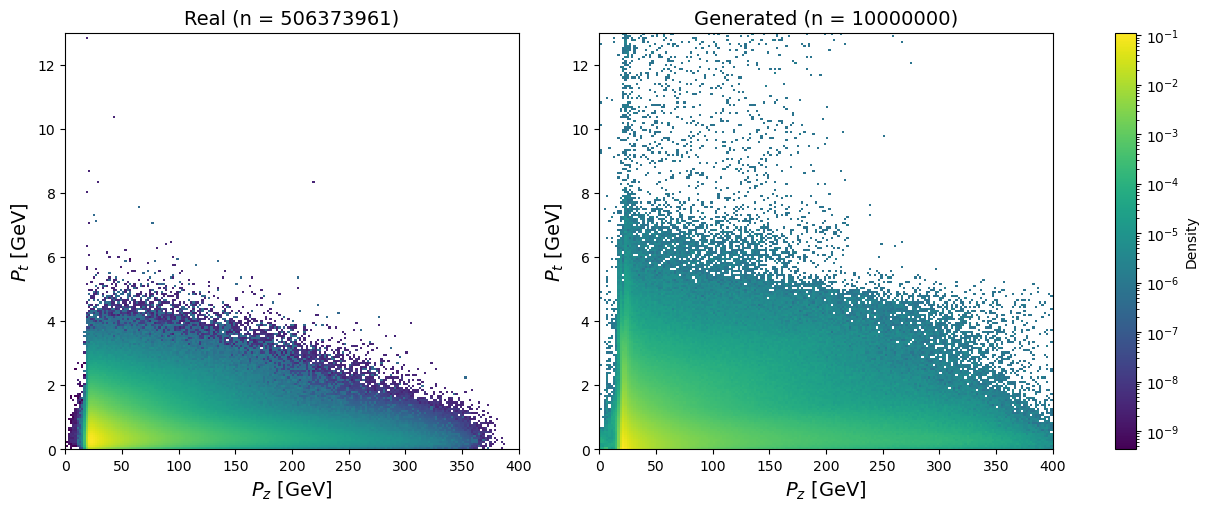

In [10]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, real_w=weights)

In [ ]:
gen_pz.min(), gen_pz.max(), gen_pt.min(), gen_pt.max()